# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [4]:
# Encontrar los archivos sin solicitar una nueva carga ni extraer ZIP.
def encontrar_archivo(nombre, rutas_alternativas):
    rutas = [Path('/content') / nombre] + [Path(r) / nombre for r in rutas_alternativas]
    for ruta in rutas:
        if ruta.is_file():
            return ruta
    raise FileNotFoundError(
        f'No se encontró {nombre}. Súbelo manualmente al panel de Archivos de Colab '
        f'para que quede en /content/{nombre}. Rutas revisadas: {rutas}'
    )

TEST_PATH = encontrar_archivo('test.csv', [
    '/content/data/processed', '/content/wine_challenge/data/processed'
])
CONTRACT_PATH = encontrar_archivo('data_contract.json', [
    '/content/artifacts', '/content/wine_challenge/artifacts'
])
MODEL_PATH = encontrar_archivo('champion_model.joblib', [
    '/content/artifacts', '/content/wine_challenge/artifacts'
])
METADATA_PATH = encontrar_archivo('training_metadata.json', [
    '/content/artifacts', '/content/wine_challenge/artifacts'
])

for nombre, ruta in [('Test', TEST_PATH), ('Contrato', CONTRACT_PATH),
                     ('Modelo', MODEL_PATH), ('Metadatos', METADATA_PATH)]:
    print(f'{nombre}: {ruta}')

contract = json.loads(CONTRACT_PATH.read_text(encoding='utf-8'))
training_metadata = json.loads(METADATA_PATH.read_text(encoding='utf-8'))
model = joblib.load(MODEL_PATH)
test_df = pd.read_csv(TEST_PATH)

feature_columns = contract['features']
target_column = contract['target']
champion_name = training_metadata.get('champion_name', training_metadata.get('champion', 'No especificado'))

required = feature_columns + [target_column]
missing = [col for col in required if col not in test_df.columns]
if missing:
    raise ValueError(f'Faltan columnas en test.csv: {missing}')

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()
print('Modelo campeón:', champion_name)
print('X_test:', X_test.shape, '| y_test:', y_test.shape)
print('Distribución de clases en test:')
print(y_test.value_counts().sort_index())
display(X_test.head())

Test: /content/test.csv
Contrato: /content/data_contract.json
Modelo: /content/champion_model.joblib
Metadatos: /content/training_metadata.json
Modelo campeón: LogisticRegression
X_test: (36, 13) | y_test: (36,)
Distribución de clases en test:
target
0    12
1    14
2    10
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.10,2.16,2.30,18.0,105.0,2.95,3.32,0.22,2.38,5.75,1.25,3.17,1510.0
1,12.51,1.24,2.25,17.5,85.0,2.00,0.58,0.60,1.25,5.45,0.75,1.51,650.0
2,13.87,1.90,2.80,19.4,107.0,2.95,2.97,0.37,1.76,4.50,1.25,3.40,915.0
3,11.56,2.05,3.23,28.5,119.0,3.18,5.08,0.47,1.87,6.00,0.93,3.69,465.0
4,13.67,1.25,1.92,18.0,94.0,2.10,1.79,0.32,0.73,3.80,1.23,2.46,630.0


## 2. Evaluación final

Accuracy de test: 0.9722 (97.22%)
F1 macro de test: 0.9710
Accuracy promedio de validación cruzada: 0.9791
Diferencia test - CV: -0.0068

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



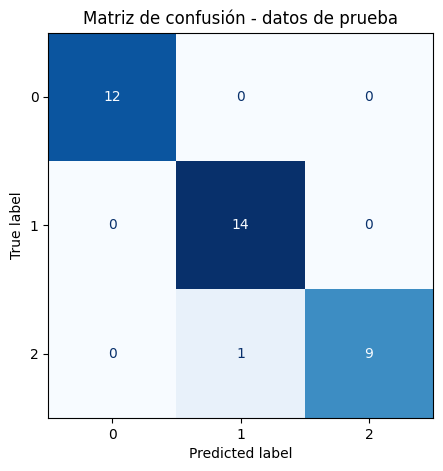

In [6]:
 from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generar predicciones
y_pred = model.predict(X_test)

# Calcular métricas
accuracy_test = accuracy_score(y_test, y_pred)
f1_macro_test = f1_score(y_test, y_pred, average='macro', zero_division=0)
accuracy_cv = training_metadata.get('cv_accuracy_mean')

print(f'Accuracy de test: {accuracy_test:.4f} ({accuracy_test:.2%})')
print(f'F1 macro de test: {f1_macro_test:.4f}')

if accuracy_cv is not None:
    print(f'Accuracy promedio de validación cruzada: {float(accuracy_cv):.4f}')
    print(f'Diferencia test - CV: {accuracy_test - float(accuracy_cv):+.4f}')

# Reporte de clasificación
print('\nReporte de clasificación:')
print(classification_report(y_test, y_pred, zero_division=0))

# Matriz de confusión
clases = list(model.classes_) if hasattr(model, 'classes_') else sorted(y_test.unique())

cm = confusion_matrix(y_test, y_pred, labels=clases)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=clases
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Matriz de confusión - datos de prueba')
plt.show()

**Análisis:**

> Al evaluar el modelo con los datos de prueba se obtuvo un accuracy del 97,22 % y un F1 macro de 0,9710, lo que indica que el modelo tiene un buen desempeño al momento de clasificar los vinos según sus características químicas. Al comparar estos resultados con el accuracy promedio de la validación cruzada, que fue del 97,91 %, se observa una diferencia de apenas 0,69 puntos porcentuales, lo que nos permite considerar que el modelo generaliza bien con datos que no había visto anteriormente y que no presenta señales importantes de sobreajuste. Además, al revisar el reporte de clasificación y la matriz de confusión, podemos observar que de los 36 registros utilizados para la prueba, 35 fueron clasificados correctamente y solamente uno presentó un error, donde un vino de la clase 2 fue clasificado como clase 1. También se puede observar que la clase 0 tuvo una precisión y recuperación del 100 %, mientras que las clases 1 y 2 presentaron algunas diferencias en sus métricas. En general, podemos concluir que el modelo seleccionado tiene un desempeño bastante bueno y estable, aunque todavía existe una pequeña posibilidad de confundir algunas clases que pueden tener características similares.

## 3. Función de inferencia

In [7]:
def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Recibe registros con las características del contrato y devuelve predicción/probabilidades."""
    if not isinstance(records, pd.DataFrame):
        raise TypeError('records debe ser un DataFrame de pandas.')

    faltantes = [col for col in feature_columns if col not in records.columns]
    if faltantes:
        raise ValueError(f'Faltan columnas necesarias: {faltantes}')

    # Conserva solo las características requeridas en el orden original del entrenamiento.
    entradas = records.loc[:, feature_columns].copy()
    resultado = pd.DataFrame(index=records.index)
    resultado['prediction'] = model.predict(entradas)

    if hasattr(model, 'predict_proba'):
        probabilidades = model.predict_proba(entradas)
        etiquetas = model.classes_
        for indice, etiqueta in enumerate(etiquetas):
            resultado[f'probability_{etiqueta}'] = probabilidades[:, indice]
    return resultado

print('Función predict() implementada.')

Función predict() implementada.


## 4. Predicción por lotes

In [8]:
new_records = X_test.iloc[:5].copy()
batch_predictions = predict(new_records)

print('Predicciones para los cinco registros de ejemplo:')
display(batch_predictions)

BATCH_PATH = REPORTS_DIR / 'batch_predictions.csv'
batch_predictions.to_csv(BATCH_PATH, index=False)
print('Archivo guardado:', BATCH_PATH)

Predicciones para los cinco registros de ejemplo:


,prediction,probability_0,probability_1,probability_2
0,0,0.999671,0.000307,0.000023
1,1,0.007051,0.540423,0.452526
2,0,0.992000,0.007664,0.000336
3,1,0.289967,0.707467,0.002565
4,1,0.033032,0.962313,0.004655


Archivo guardado: /content/reports/batch_predictions.csv


## 5. Reporte final

In [9]:
metrics = {
    'champion_model': champion_name,
    'cv_accuracy_mean': float(accuracy_cv) if accuracy_cv is not None else None,
    'test_accuracy': float(accuracy_test),
    'test_f1_macro': float(f1_macro_test),
    'test_samples': int(len(y_test)),
    'class_labels': [str(c) for c in clases],
    'confusion_matrix': cm.tolist(),
}

METRICS_PATH = REPORTS_DIR / 'test_metrics.json'
METRICS_PATH.write_text(json.dumps(metrics, indent=4, ensure_ascii=False), encoding='utf-8')
print('Archivo guardado:', METRICS_PATH)
print(json.dumps(metrics, indent=2, ensure_ascii=False))

Archivo guardado: /content/reports/test_metrics.json
{
  "champion_model": "LogisticRegression",
  "cv_accuracy_mean": 0.9790640394088669,
  "test_accuracy": 0.9722222222222222,
  "test_f1_macro": 0.9709618874773139,
  "test_samples": 36,
  "class_labels": [
    "0",
    "1",
    "2"
  ],
  "confusion_matrix": [
    [
      12,
      0,
      0
    ],
    [
      0,
      14,
      0
    ],
    [
      0,
      1,
      9
    ]
  ]
}


In [10]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | |
| Accuracy CV | |
| Accuracy test | |
| F1 macro test | |
| Clases más confundidas | |
| Principal limitación | |



In [12]:
# Identificar los errores de clasificación
errores = []

for i in range(len(clases)):
    for j in range(len(clases)):
        if i != j and cm[i, j] > 0:
            errores.append((
                int(cm[i, j]),
                clases[i],
                clases[j]
            ))

# Ordenar errores de mayor a menor
errores.sort(reverse=True)

# Identificar las clases más confundidas
if errores:
    mayor = errores[0]
    clases_confundidas = f'{mayor[1]} → {mayor[2]} ({mayor[0]} caso(s))'
else:
    clases_confundidas = 'Ninguna en el conjunto de prueba'

# Crear tabla de resumen
resumen = pd.DataFrame({
    'Elemento': [
        'Modelo campeón',
        'Accuracy CV',
        'Accuracy test',
        'F1 macro test',
        'Clases más confundidas',
        'Principal limitación'
    ],
    'Resultado': [
        champion_name,
        f'{float(accuracy_cv):.4f}' if accuracy_cv is not None else 'No disponible',
        f'{accuracy_test:.4f}',
        f'{f1_macro_test:.4f}',
        clases_confundidas,
        f'Conjunto de prueba pequeño ({len(y_test)} registros)'
    ]
})

display(resumen)

# Verificar archivos generados
assert METRICS_PATH.exists()
assert BATCH_PATH.exists()

print('Challenge 3 completado: se generaron los dos archivos solicitados.')

,Elemento,Resultado
0,Modelo campeón,LogisticRegression
1,Accuracy CV,0.9791
2,Accuracy test,0.9722
3,F1 macro test,0.9710
4,Clases más confundidas,2 → 1 (1 caso(s))
5,Principal limitación,Conjunto de prueba pequeño (36 registros)


Challenge 3 completado: se generaron los dos archivos solicitados.


## Checklist

- [ ] Evalué únicamente el modelo campeón.
- [ ] No reajusté hiperparámetros después de observar test.
- [ ] Implementé validación básica del esquema de entrada.
- [ ] Generé predicciones por lotes.
- [ ] Guardé las métricas finales.